## 实验报告02：NumPy、SciPy、Matplotlib与 pandas 数据处理

## ⼀、实验环境与提交要求

1.  请使⽤独⽴的  conda  虚拟环境完成实验，不得使⽤  base  环境。在该环境中准备 Python 3 、 Jupyter Notebook 、 NumPy 、 SciPy 、 Matplotlib  和  pandas 。
2.  请先将第⼀个代码框中的学号修改为⾃⼰的学号，再按顺序运⾏各代码框。可在 PyCharm  或  VS Code  中完成。 
3.  使⽤  Markdown  单元格解释关键结果；使⽤代码单元格完成计算。图表须有标题、 坐标轴标签和必要的图例。 
4.  涉及随机抽样的实验请设置固定种⼦。 
5.  提交前重启内核并运⾏全部代码，检查依赖和输出。只提交命名为  20244080125_曹俊华 _exp02.ipynb  的  Notebook 

## 1.1 第⼀个代码框：⾝份与环境记录

In [9]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20190010
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")


[Conda 环境] exp01
[学号]       20190010
[机器指纹] 4cb1b7fabb4fe7ff
[RUN_ID]   20190010-4cb1b7fabb4fe7ff


## 实验 1：NumPy数组、数据类型与索引
1.1 数组创建与数据类型

In [10]:
import numpy as np

# 1. 分别创建整数、浮点数和布尔值 ndarray
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

for arr in [arr_int, arr_float, arr_bool]:
    print(f"数组: {arr}, dtype: {arr.dtype}, shape: {arr.shape}, ndim: {arr.ndim}")

# 解释：NumPy 数组要求所有元素必须是相同的数据类型（同质），而 Python 列表可以混合不同类型。
# NumPy 在底层使用连续的内存块存储，运算速度远快于列表。

数组: [1 2 3], dtype: int64, shape: (3,), ndim: 1
数组: [1. 2. 3.], dtype: float64, shape: (3,), ndim: 1
数组: [ True False  True], dtype: bool, shape: (3,), ndim: 1


1.2 形状变换与元素总数

In [11]:
# 2. 用 np.arange(12) 创建数组并变形
arr_1d = np.arange(12)
arr_3x4 = arr_1d.reshape(3, 4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)

print("(3,4) 形状:\n", arr_3x4)
print("(2,3,2) 形状:\n", arr_2x3x2)
# 解释：改变形状时，新形状的元素总数必须与原数组的元素总数相等。12 = 3*4 = 2*3*2。

(3,4) 形状:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2) 形状:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


1.3 数组索引

In [12]:
# 3. 对 (3, 4) 数组进行索引
print("第2行:", arr_3x4[1, :], "形状:", arr_3x4[1, :].shape)
print("第1至第3列:", arr_3x4[:, 0:3], "形状:", arr_3x4[:, 0:3].shape)
print("大于6的元素:", arr_3x4[arr_3x4 > 6], "形状:", arr_3x4[arr_3x4 > 6].shape) # 注意：布尔索引返回的是一维数组

第2行: [4 5 6 7] 形状: (4,)
第1至第3列: [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状: (3, 3)
大于6的元素: [ 7  8  9 10 11] 形状: (5,)


1.4 逻辑筛选

In [13]:
# 4. np.arange(10) 筛选
arr_10 = np.arange(10)
print("小于2或大于7:", arr_10[(arr_10 < 2) | (arr_10 > 7)])
print("大于3且小于7:", arr_10[(arr_10 > 3) & (arr_10 < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]


1.5 矩阵乘法与逐元素乘法

In [14]:
# 5. 对比 * 和 @
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("逐元素乘法 (* 或 np.multiply):\n", A * B)
print("矩阵乘法 (@ 或 np.matmul):\n", A @ B)
# 解释：* 是对应位置元素相乘；@ 遵循线性代数矩阵乘法规则（行乘列求和）。

逐元素乘法 (* 或 np.multiply):
 [[ 5 12]
 [21 32]]
矩阵乘法 (@ 或 np.matmul):
 [[19 22]
 [43 50]]


## 实验 2：随机抽样、统计与缺失值
2.1 模拟成绩与统计

In [15]:
import numpy as np

# 1. 生成 1000 个模拟成绩并限制在 0~100
np.random.seed(42) # 固定种子保证可重复
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数: {len(scores)}")
print(f"最小值: {np.min(scores):.2f}, 最大值: {np.max(scores):.2f}")
print(f"均值: {np.mean(scores):.2f}, 标准差: {np.std(scores):.2f}")
print(f"极差: {np.max(scores) - np.min(scores):.2f}")

样本数: 1000
最小值: 37.59, 最大值: 100.00
均值: 70.18, 标准差: 9.76
极差: 62.41


2.2 随机抽样

In [16]:
# 2. 均匀抽样与加权抽样
arr_pop = np.arange(1, 11)
# 均匀（不放回）
sample_uniform = np.random.choice(arr_pop, size=5, replace=False)
# 加权（按数值大小成比例）
probs = arr_pop / arr_pop.sum()
sample_weighted = np.random.choice(arr_pop, size=5, replace=False, p=probs)
print("均匀抽样:", sample_uniform)
print("加权抽样:", sample_weighted)

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]


2.3 随机排列与打乱

In [17]:
# 3. 随机排列与原地打乱
arr_perm = np.arange(5)
print("原数组:", arr_perm)
permuted = np.random.permutation(arr_perm)
print("permutation (返回新数组):", permuted, "原数组保持不变:", arr_perm)
np.random.shuffle(arr_perm)
print("shuffle (原地打乱):", arr_perm)

原数组: [0 1 2 3 4]
permutation (返回新数组): [4 0 2 1 3] 原数组保持不变: [0 1 2 3 4]
shuffle (原地打乱): [0 4 1 3 2]


2.4 缺失值处理

In [18]:
# 4. 插入 np.nan 并统计
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print(f"普通均值: {np.mean(scores_nan)}")  # 结果为 nan
print(f"忽略缺失值均值: {np.nanmean(scores_nan):.2f}")
print(f"缺失值个数: {np.isnan(scores_nan).sum()}")
# 解释：普通统计函数遇到 nan 会直接返回 nan，必须使用带 nan 前缀的函数（如 np.nanmean）。

普通均值: nan
忽略缺失值均值: 70.20
缺失值个数: 3


2.5 准备实验 4 的内存表格

In [19]:
import pandas as pd

# 5. 整理成 DataFrame
df_exp2 = pd.DataFrame({
    "Index": np.arange(len(scores_nan)),
    "Score": scores_nan
})
print("内存表格准备完毕，包含缺失值数据。")

内存表格准备完毕，包含缺失值数据。


## 实验 3：SciPy 数值计算与 Matplotlib 可视化
3.1 线性方程组求解

In [20]:
import scipy.linalg
import numpy as np

# 1. 解方程组 3x + y = 9, x + 2y = 8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x = scipy.linalg.solve(A, b)
print("解 x:", x)
print("代入验证 A@x:", A @ x) # 应等于 [9, 8]

解 x: [2. 3.]
代入验证 A@x: [9. 8.]


3.2 求方程根

In [21]:
from scipy.optimize import root

# 2. 求 x^2 - 2 = 0 的根
def func(x): return x**2 - 2
res_pos = root(func, x0=1) # 猜测正根
res_neg = root(func, x0=-1) # 猜测负根
print(f"正根: {res_pos.x[0]:.4f}, 成功: {res_pos.success}, 函数值: {res_pos.fun[0]:.2e}")
print(f"负根: {res_neg.x[0]:.4f}, 成功: {res_neg.success}, 函数值: {res_neg.fun[0]:.2e}")

正根: 1.4142, 成功: True, 函数值: -8.88e-16
负根: -1.4142, 成功: True, 函数值: -8.88e-16


3.3 求函数极小值

In [22]:
from scipy.optimize import minimize

# 3. 求 f(x) = x^2 + x + 2 极小值
res_min = minimize(lambda x: x**2 + x + 2, x0=0)
print(f"极小值点 x = {res_min.x[0]:.2f}")
print(f"极小值 y = {res_min.fun:.2f}")
# 解析结果对比：导数为 2x+1=0 => x=-0.5, y=1.75。结果吻合。

极小值点 x = -0.50
极小值 y = 1.75


3.4 独立样本 t 检验

In [23]:
from scipy.stats import ttest_ind

# 4. 独立样本 t 检验
np.random.seed(42)
group1 = np.random.normal(0, 1, 100)
group2 = np.random.normal(1, 1, 100)
t_stat, p_val = ttest_ind(group1, group2)
print(f"t统计量: {t_stat:.4f}, p值: {p_val:.4e}")
if p_val < 0.05:
    print("在 0.05 显著性水平下，拒绝原假设，两组样本均值存在显著差异。")
else:
    print("在 0.05 显著性水平下，不能拒绝原假设。")

t统计量: -8.5515, p值: 3.2930e-15
在 0.05 显著性水平下，拒绝原假设，两组样本均值存在显著差异。


3.5 Matplotlib 可视化

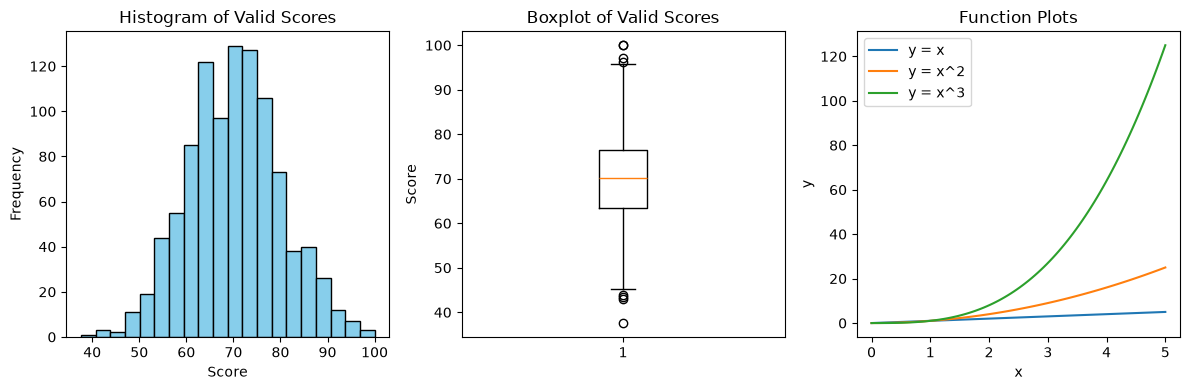

In [24]:
import matplotlib.pyplot as plt

# 5. 画图
plt.figure(figsize=(12, 4))

# 图1：直方图
plt.subplot(1, 3, 1)
valid_scores = scores[~np.isnan(scores)]
plt.hist(valid_scores, bins=20, color='skyblue', edgecolor='black')
plt.title("Histogram of Valid Scores")
plt.xlabel("Score"); plt.ylabel("Frequency")

# 图2：箱线图
plt.subplot(1, 3, 2)
plt.boxplot(valid_scores)
plt.title("Boxplot of Valid Scores")
plt.ylabel("Score")

# 图3：折线图
plt.subplot(1, 3, 3)
x_vals = np.linspace(0, 5, 100)
plt.plot(x_vals, x_vals, label='y = x')
plt.plot(x_vals, x_vals**2, label='y = x^2')
plt.plot(x_vals, x_vals**3, label='y = x^3')
plt.title("Function Plots")
plt.xlabel("x"); plt.ylabel("y")
plt.legend()

plt.tight_layout()
plt.show()

 实验 4：pandas Series、DataFrame
4.1 创建 DataFrame 与基础操作

In [25]:
import pandas as pd

# 1. 创建 DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("前3行:\n", df.head(3))
print("基本统计:\n", df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


4.2 loc 与 iloc 读取

In [26]:
# 2. 读取 Carol
print("loc 读取:\n", df.loc["Carol"])
print("iloc 读取:\n", df.iloc[2])
print("平均分不低于80:\n", df[df["Average"] >= 80])

loc 读取:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc 读取:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


4.3 均值计算

In [27]:
# 3. 列均值与行均值
print("列均值:\n", df[["Math", "English", "Python"]].mean(axis=0))
print("每名学生行均值:\n", df[["Math", "English", "Python"]].mean(axis=1))

列均值:
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生行均值:
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


4.4 apply, agg, rank

In [28]:
# 4. 最高分、聚合、排名
df["Max_Score"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("每科最小值、均值、最大值:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))
df["Math_Rank"] = df["Math"].rank(ascending=False) # 分数高的排前面
print(df[["Math", "Math_Rank"]])

每科最小值、均值、最大值:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
       Math  Math_Rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


4.5 分组与 transform

In [29]:
# 5. 分组统计与 transform
group_stats = df.groupby("Group").agg(
    Count=("Group", "size"),
    Math_Mean=("Math", "mean"),
    English_Mean=("English", "mean"),
    Python_Mean=("Python", "mean")
)
print("分组统计:\n", group_stats)
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")

分组统计:
        Count  Math_Mean  English_Mean  Python_Mean
Group                                             
A          3  79.666667     83.333333    87.000000
B          3  80.000000     78.333333    80.333333


4.6 filter 筛选组

In [30]:
# 6. 过滤 Python 平均分 >= 80 的组
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)
print("保留的组和学生:\n", filtered_df[["Group", "Python"]])

保留的组和学生:
       Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


4.7 协方差与相关系数

In [31]:
# 7. 协方差与皮尔森相关系数
cov_matrix = df[["Math", "English", "Python"]].cov()
corr_matrix = df[["Math", "English", "Python"]].corr()

print("协方差矩阵:\n", cov_matrix)
print("皮尔森相关系数矩阵:\n", corr_matrix)
# 解释示例：Math 和 English 的协方差为正，说明两者同向变化。
# 相关系数接近 1，说明强正线性相关；接近 0 表示弱相关。具体数值看输出结果。

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
皮尔森相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
